# URL Phishing Detection — Final Modeling

## Objective

In this notebook, I develop and evaluate a URL phishing classifier using the dataset prepared in `05_url_dataset_construction.ipynb`.

My earlier experiments with PhiUSIIL and LegitPhish revealed substantial structural biases that could inflate model performance.

I therefore use the newly constructed dataset, which contains more diverse legitimate and phishing URL structures.

I reuse my existing URL feature extractor and compare CPU-friendly machine learning models using fixed, hostname-aware dataset partitions.

My evaluation focuses on phishing precision, recall, F1-score, false positives, and generalization across unfamiliar hostnames.

I reserve the test partition for final evaluation and use only training and validation data during model selection.

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np

RANDOM_STATE = 42

# I configure portable project paths.
PROJECT_ROOT = Path.cwd().resolve().parent

DATA_DIR = PROJECT_ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
SPLIT_DIR = PROCESSED_DIR / "splits"

MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"

# I verify that the final URL partitions are available.
required_files = [
    "url_v2_train.csv",
    "url_v2_val.csv",
    "url_v2_test.csv"
]

print("FINAL URL DATASET VERIFICATION")

print("Project root:", PROJECT_ROOT)

for filename in required_files:
    path = SPLIT_DIR / filename

    assert path.is_file(), f"Missing dataset: {path}"

    print(f"{filename}: FOUND")

print("\nDataset file verification: PASSED")

FINAL URL DATASET VERIFICATION
Project root: C:\Users\JONATHAN\Desktop\WORK\spam-phishing-detector
url_v2_train.csv: FOUND
url_v2_val.csv: FOUND
url_v2_test.csv: FOUND

Dataset file verification: PASSED


In [4]:
# I load only the training and validation partitions.
url_train = pd.read_csv(
    SPLIT_DIR / "url_v2_train.csv"
)

url_val = pd.read_csv(
    SPLIT_DIR / "url_v2_val.csv"
)

print("TRAINING DATA")
print("Shape:", url_train.shape)
print("Columns:", url_train.columns.tolist())

print("\nVALIDATION DATA")
print("Shape:", url_val.shape)
print("Columns:", url_val.columns.tolist())

print("\nTRAINING LABEL DISTRIBUTION")
print(url_train["label"].value_counts().sort_index())

print("\nVALIDATION LABEL DISTRIBUTION")
print(url_val["label"].value_counts().sort_index())

TRAINING DATA
Shape: (90840, 3)
Columns: ['url', 'label', 'source']

VALIDATION DATA
Shape: (19467, 3)
Columns: ['url', 'label', 'source']

TRAINING LABEL DISTRIBUTION
label
0    52478
1    38362
Name: count, dtype: int64

VALIDATION LABEL DISTRIBUTION
label
0    11246
1     8221
Name: count, dtype: int64


## 1. URL Feature Preparation

I reuse the URL feature extractor developed during my earlier PhiUSIIL investigation.

The extractor generates 21 numerical features directly from URL strings, including URL length, hostname structure, character patterns, path depth, and HTTPS usage.

I apply the same feature extraction process to the training and validation partitions without using classification labels or dataset source identifiers.

I verify feature consistency and numerical validity before proceeding with model training.

The test partition remains untouched until final evaluation.

In [7]:
import sys
import importlib

# I make the project root available for local module imports.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.url_features

# I reload the module to use the latest saved implementation.
importlib.reload(src.url_features)

from src.url_features import extract_features_dataframe

print("URL feature extractor imported successfully.")

URL feature extractor imported successfully.


In [9]:
import time

# I extract features from the training URLs.
start_time = time.perf_counter()

X_url_train = extract_features_dataframe(
    url_train["url"]
)

train_extraction_time = time.perf_counter() - start_time

print("TRAINING FEATURE EXTRACTION")
print("Shape:", X_url_train.shape)
print(f"Time: {train_extraction_time:.2f} seconds")


# I extract features from the validation URLs.
start_time = time.perf_counter()

X_url_val = extract_features_dataframe(
    url_val["url"]
)

val_extraction_time = time.perf_counter() - start_time

print("\nVALIDATION FEATURE EXTRACTION")
print("Shape:", X_url_val.shape)
print(f"Time: {val_extraction_time:.2f} seconds")


# I retain the labels separately.
y_url_train = url_train["label"].reset_index(drop=True)
y_url_val = url_val["label"].reset_index(drop=True)

TRAINING FEATURE EXTRACTION
Shape: (90840, 21)
Time: 8.04 seconds

VALIDATION FEATURE EXTRACTION
Shape: (19467, 21)
Time: 1.81 seconds


In [11]:
# I verify the expected feature dimensions.
assert X_url_train.shape == (len(url_train), 21)
assert X_url_val.shape == (len(url_val), 21)

# I confirm that both partitions use identical features.
assert X_url_train.columns.equals(X_url_val.columns)

# I verify that all feature values are numerical.
assert all(
    pd.api.types.is_numeric_dtype(dtype)
    for dtype in X_url_train.dtypes
)

# I check for missing and infinite values.
assert np.isfinite(X_url_train.to_numpy()).all()
assert np.isfinite(X_url_val.to_numpy()).all()

# I verify that features and labels are aligned.
assert len(X_url_train) == len(y_url_train)
assert len(X_url_val) == len(y_url_val)

print("URL FEATURE VALIDATION")
print("Training:", X_url_train.shape)
print("Validation:", X_url_val.shape)
print("Features:", X_url_train.shape[1])
print("Missing/infinite values: NONE")
print("Feature alignment: PASSED")
print("Overall validation: PASSED")

URL FEATURE VALIDATION
Training: (90840, 21)
Validation: (19467, 21)
Features: 21
Missing/infinite values: NONE
Feature alignment: PASSED
Overall validation: PASSED


## 2. URL Classification Baselines

I establish two baseline classifiers before training my final URL detection models.

The first is a majority-class classifier that always predicts the most common training label.

The second uses a simple structural rule: classify a URL as phishing if it uses HTTP or contains a non-empty path.

This rule achieved unusually strong results during my PhiUSIIL investigation, revealing substantial structural bias in that dataset.

I evaluate both baselines on the new hostname-aware validation partition to determine whether the same shortcut remains effective.

I compare accuracy, phishing precision, recall, F1-score, and confusion matrices.

In [14]:
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# I use a consistent evaluation function across URL experiments.
def evaluate_url_model(model_name, y_true, y_pred):

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

    print(f"\n{model_name.upper()} RESULTS")

    for metric, value in results.items():
        if metric == "Model":
            print(f"{metric}: {value}")
        else:
            print(f"{metric}: {value:.4f}")

    print("\nCONFUSION MATRIX")
    print(
        confusion_matrix(
            y_true,
            y_pred,
            labels=[0, 1]
        )
    )

    print("\nCLASSIFICATION REPORT")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=["Legitimate", "Phishing"],
            zero_division=0
        )
    )

    return results


print("Evaluation function ready.")

Evaluation function ready.


In [16]:
# I train a classifier that always predicts the majority class.
url_baseline = DummyClassifier(
    strategy="most_frequent"
)

url_baseline.fit(
    X_url_train,
    y_url_train
)

url_baseline_predictions = url_baseline.predict(
    X_url_val
)

url_baseline_results = evaluate_url_model(
    "Majority Class",
    y_url_val,
    url_baseline_predictions
)


MAJORITY CLASS RESULTS
Model: Majority Class
Accuracy: 0.5777
Precision: 0.0000
Recall: 0.0000
F1: 0.0000

CONFUSION MATRIX
[[11246     0]
 [ 8221     0]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.58      1.00      0.73     11246
    Phishing       0.00      0.00      0.00      8221

    accuracy                           0.58     19467
   macro avg       0.29      0.50      0.37     19467
weighted avg       0.33      0.58      0.42     19467



In [18]:
# I reproduce the structural rule investigated in PhiUSIIL.
url_rule_predictions = (
    (X_url_val["is_https"] == 0)
    | (X_url_val["path_length"] > 0)
).astype(int)

url_rule_results = evaluate_url_model(
    "HTTP or Non-Empty Path",
    y_url_val,
    url_rule_predictions
)


HTTP OR NON-EMPTY PATH RESULTS
Model: HTTP or Non-Empty Path
Accuracy: 0.4026
Precision: 0.4101
Recall: 0.9451
F1: 0.5720

CONFUSION MATRIX
[[   68 11178]
 [  451  7770]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.13      0.01      0.01     11246
    Phishing       0.41      0.95      0.57      8221

    accuracy                           0.40     19467
   macro avg       0.27      0.48      0.29     19467
weighted avg       0.25      0.40      0.25     19467



## 3. URL Classification — Logistic Regression

I train a Logistic Regression classifier using the 21 numerical URL features extracted from the new dataset.

I use the same feature representation and modeling configuration as my earlier PhiUSIIL experiment to examine whether the model remains effective on a dataset with more diverse URL structures.

I standardize the numerical features using StandardScaler and fit the entire pipeline using training data only.

I evaluate the classifier on the fixed hostname-aware validation partition, focusing on phishing precision, recall, F1-score, and false positives.

Unlike my earlier investigation, I now have evidence that a simple HTTP-or-path classification rule performs poorly on this dataset. However, I will continue examining feature influence and potential collection bias before considering the model suitable for deployment.

In [21]:
import time

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# I build my Logistic Regression pipeline.
url_logreg_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight=None,
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

# I measure the time required to train the classifier.
start_time = time.perf_counter()

url_logreg_pipeline.fit(
    X_url_train,
    y_url_train
)

url_logreg_training_time = (
    time.perf_counter() - start_time
)

print("URL Logistic Regression trained successfully.")
print(f"Training time: {url_logreg_training_time:.2f} seconds")

print(
    "Features used:",
    url_logreg_pipeline.n_features_in_
)

URL Logistic Regression trained successfully.
Training time: 1.22 seconds
Features used: 21


In [23]:
# I generate predictions on the validation partition.
url_logreg_predictions = url_logreg_pipeline.predict(
    X_url_val
)

# I retain probability estimates for later analysis.
url_logreg_probabilities = (
    url_logreg_pipeline.predict_proba(X_url_val)[:, 1]
)

print("Validation predictions generated successfully.")

print(
    "Predicted phishing URLs:",
    int(url_logreg_predictions.sum())
)

print(
    "Actual phishing URLs:",
    int(y_url_val.sum())
)

Validation predictions generated successfully.
Predicted phishing URLs: 9256
Actual phishing URLs: 8221


In [25]:
# I evaluate Logistic Regression on the hostname-aware validation set.
url_logreg_results = evaluate_url_model(
    "Logistic Regression",
    y_url_val,
    url_logreg_predictions
)


LOGISTIC REGRESSION RESULTS
Model: Logistic Regression
Accuracy: 0.8787
Precision: 0.8166
Recall: 0.9194
F1: 0.8649

CONFUSION MATRIX
[[9548 1698]
 [ 663 7558]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.94      0.85      0.89     11246
    Phishing       0.82      0.92      0.86      8221

    accuracy                           0.88     19467
   macro avg       0.88      0.88      0.88     19467
weighted avg       0.89      0.88      0.88     19467



## 4. URL Classification — Histogram Gradient Boosting

I train a histogram-based gradient boosting classifier to investigate whether nonlinear relationships between URL features improve phishing detection.

My Logistic Regression model achieved an F1-score of 86.49%, but incorrectly classified 1,698 legitimate URLs as phishing.

I want to determine whether a tree-based classifier can reduce false positives while maintaining strong phishing recall.

I use the same 21 features, training partition, and validation partition to keep the comparison consistent.

I begin with a restrained configuration rather than performing an extensive hyperparameter search.

In [28]:
import time

from sklearn.ensemble import HistGradientBoostingClassifier

# I train a tree-based model using the same URL features.
url_hgb_model = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_iter=150,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=RANDOM_STATE
)

# I measure the training time.
start_time = time.perf_counter()

url_hgb_model.fit(
    X_url_train,
    y_url_train
)

hgb_training_time = time.perf_counter() - start_time

print("Histogram Gradient Boosting trained successfully.")
print(f"Training time: {hgb_training_time:.2f} seconds")
print("Features used:", url_hgb_model.n_features_in_)
print("Boosting iterations:", url_hgb_model.n_iter_)

Histogram Gradient Boosting trained successfully.
Training time: 3.44 seconds
Features used: 21
Boosting iterations: 150


In [30]:
# I generate predictions on the fixed validation partition.
url_hgb_predictions = url_hgb_model.predict(
    X_url_val
)

# I retain predicted probabilities for later analysis.
url_hgb_probabilities = url_hgb_model.predict_proba(
    X_url_val
)[:, 1]

print("Validation predictions generated successfully.")

print(
    "Predicted phishing URLs:",
    int(url_hgb_predictions.sum())
)

print(
    "Actual phishing URLs:",
    int(y_url_val.sum())
)

Validation predictions generated successfully.
Predicted phishing URLs: 9373
Actual phishing URLs: 8221


In [32]:
# I evaluate the tree-based classifier.
url_hgb_results = evaluate_url_model(
    "Histogram Gradient Boosting",
    y_url_val,
    url_hgb_predictions
)


HISTOGRAM GRADIENT BOOSTING RESULTS
Model: Histogram Gradient Boosting
Accuracy: 0.9087
Precision: 0.8437
Recall: 0.9619
F1: 0.8989

CONFUSION MATRIX
[[9781 1465]
 [ 313 7908]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.97      0.87      0.92     11246
    Phishing       0.84      0.96      0.90      8221

    accuracy                           0.91     19467
   macro avg       0.91      0.92      0.91     19467
weighted avg       0.92      0.91      0.91     19467



## 5. Source-Level Model Evaluation

I investigate whether my URL classifiers perform consistently across the original dataset sources.

Histogram Gradient Boosting improved validation performance compared with Logistic Regression, achieving an F1-score of 89.89%.

However, I want to determine whether this improvement reflects useful URL characteristics or patterns associated with the datasets' collection methods.

I examine the relationship between data source and classification labels, then calculate model performance separately for each source.

I retain the source column for evaluation only and do not use it as a predictive feature.

In [35]:
# I inspect the relationship between dataset source and labels.

print("TRAINING SOURCE DISTRIBUTION")

display(
    pd.crosstab(
        url_train["source"],
        url_train["label"],
        margins=True
    )
)

print("\nVALIDATION SOURCE DISTRIBUTION")

display(
    pd.crosstab(
        url_val["source"],
        url_val["label"],
        margins=True
    )
)

print("\nVALIDATION PHISHING RATE BY SOURCE")

source_label_summary = (
    url_val
    .groupby("source")
    .agg(
        records=("label", "size"),
        phishing_count=("label", "sum"),
        phishing_rate=("label", "mean")
    )
    .reset_index()
)

display(source_label_summary.round(4))

TRAINING SOURCE DISTRIBUTION


label,0,1,All
source,,,
Wangchuk_2026_CommonCrawl_Phishtank,52478,38362,90840
All,52478,38362,90840



VALIDATION SOURCE DISTRIBUTION


label,0,1,All
source,,,
Wangchuk_2026_CommonCrawl_Phishtank,11246,8221,19467
All,11246,8221,19467



VALIDATION PHISHING RATE BY SOURCE


,source,records,phishing_count,phishing_rate
0,Wangchuk_2026_CommonCrawl_Phishtank,19467,8221,0.4223


In [37]:
# I combine validation labels, predictions, and source identifiers.

url_source_analysis = pd.DataFrame({
    "source": url_val["source"].to_numpy(),
    "actual": y_url_val.to_numpy(),
    "predicted": url_hgb_predictions
})

source_results = []

for source_name, group in url_source_analysis.groupby("source"):

    y_true = group["actual"]
    y_pred = group["predicted"]

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    source_results.append({
        "source": source_name,
        "records": len(group),
        "phishing_rate": y_true.mean(),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "false_positives": int(fp),
        "false_negatives": int(fn)
    })

source_performance = pd.DataFrame(source_results)

print("HISTOGRAM GRADIENT BOOSTING — SOURCE PERFORMANCE")

display(source_performance.round(4))

HISTOGRAM GRADIENT BOOSTING — SOURCE PERFORMANCE


,source,records,phishing_rate,accuracy,precision,recall,f1,false_positives,false_negatives
0,Wangchuk_2026_CommonCrawl_Phishtank,19467,0.4223,0.9087,0.8437,0.9619,0.8989,1465,313


### Source-Level Evaluation Findings

The constructed dataset contains a single source identifier:
`Wangchuk_2026_CommonCrawl_Phishtank`.

This identifier represents the published dataset as a whole rather than the original collection source of each URL.

Consequently, the source-level evaluation reproduces my overall validation results and does not provide an independent assessment of performance across Common Crawl and PhishTank.

Although my hostname-aware partitions prevent identical hostnames from appearing across training and validation sets, they do not eliminate potential collection-source bias.

I therefore treat the current validation results as evidence of performance within this published dataset, rather than proof of generalization to independently collected URLs.

## 6. Model Error Analysis and Feature Dependence

I examine the validation errors of my Histogram Gradient Boosting classifier to understand its strengths and limitations.

My model correctly identifies 96.19% of phishing URLs but incorrectly flags 1,465 legitimate URLs.

I investigate whether these errors are concentrated in particular URL structures, including HTTPS usage, path presence, and query strings.

I also measure permutation feature importance on a stratified validation sample to identify which features contribute most strongly to phishing F1-score.

These analyses help me assess model behavior before final selection, without using the held-out test partition.

In [41]:
from sklearn.metrics import confusion_matrix

# I create a validation analysis table.
url_error_analysis = pd.DataFrame({
    "actual": y_url_val.to_numpy(),
    "predicted": url_hgb_predictions,
    "is_https": X_url_val["is_https"].to_numpy(),
    "has_path": (
        X_url_val["path_length"].to_numpy() > 0
    ),
    "has_query": X_url_val["has_query"].to_numpy()
})

# I define mutually exclusive groups for each URL characteristic.
url_subgroups = {
    "HTTPS": url_error_analysis["is_https"] == 1,
    "HTTP / Non-HTTPS": url_error_analysis["is_https"] == 0,
    "Non-empty path": url_error_analysis["has_path"],
    "Empty path": ~url_error_analysis["has_path"],
    "Has query": url_error_analysis["has_query"] == 1,
    "No query": url_error_analysis["has_query"] == 0
}

subgroup_results = []

for group_name, mask in url_subgroups.items():

    group = url_error_analysis.loc[mask]

    tn, fp, fn, tp = confusion_matrix(
        group["actual"],
        group["predicted"],
        labels=[0, 1]
    ).ravel()

    legitimate_count = tn + fp
    phishing_count = tp + fn

    subgroup_results.append({
        "subgroup": group_name,
        "records": len(group),
        "legitimate": legitimate_count,
        "phishing": phishing_count,
        "accuracy": (tp + tn) / len(group),
        "phishing_recall": (
            tp / phishing_count
            if phishing_count else np.nan
        ),
        "false_positive_rate": (
            fp / legitimate_count
            if legitimate_count else np.nan
        ),
        "false_positives": fp,
        "false_negatives": fn
    })

url_subgroup_results = pd.DataFrame(subgroup_results)

print("URL STRUCTURAL SUBGROUP PERFORMANCE")

display(url_subgroup_results.round(4))

URL STRUCTURAL SUBGROUP PERFORMANCE


,subgroup,records,legitimate,phishing,accuracy,phishing_recall,false_positive_rate,false_positives,false_negatives
0,HTTPS,17207,9579,7628,0.9070,0.9666,0.1405,1346,255
1,HTTP / Non-HTTPS,2260,1667,593,0.9217,0.9022,0.0714,119,58
2,Non-empty path,18642,11134,7508,0.9085,0.9592,0.1257,1399,306
3,Empty path,825,112,713,0.9115,0.9902,0.5893,66,7
4,Has query,3246,2772,474,0.8207,0.8629,0.1865,517,65
5,No query,16221,8474,7747,0.9263,0.9680,0.1119,948,248


In [43]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

# I select a reproducible stratified validation sample.
importance_indices, _ = train_test_split(
    np.arange(len(y_url_val)),
    train_size=5000,
    stratify=y_url_val,
    random_state=RANDOM_STATE
)

X_importance = X_url_val.iloc[importance_indices]
y_importance = y_url_val.iloc[importance_indices]

# I calculate permutation importance using phishing F1-score.
importance_start = time.perf_counter()

url_permutation_importance = permutation_importance(
    url_hgb_model,
    X_importance,
    y_importance,
    scoring="f1",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=1
)

importance_time = time.perf_counter() - importance_start

url_feature_importance = (
    pd.DataFrame({
        "feature": X_importance.columns,
        "importance_mean": (
            url_permutation_importance.importances_mean
        ),
        "importance_std": (
            url_permutation_importance.importances_std
        )
    })
    .sort_values(
        "importance_mean",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    f"Permutation importance completed in "
    f"{importance_time:.2f} seconds"
)

display(url_feature_importance.head(15).round(4))

Permutation importance completed in 4.99 seconds


,feature,importance_mean,importance_std
0,special_char_count,0.1535,0.0051
1,hostname_length,0.1363,0.0053
2,path_length,0.0784,0.0027
3,subdomain_count,0.0515,0.0019
4,url_length,0.0488,0.0014
5,suspicious_keyword_count,0.0110,0.0012
6,equal_sign_count,0.0103,0.0008
7,query_length,0.0070,0.0008
8,hyphen_count,0.0023,0.0015
9,percent_encoding_count,0.0019,0.0005


## 7. Classification Threshold Analysis

I investigate whether adjusting the classification threshold can reduce false-positive predictions without sacrificing too much phishing recall.

My Histogram Gradient Boosting classifier achieves 89.89% phishing F1-score at the default threshold of 0.50. However, it incorrectly flags 1,465 legitimate URLs as phishing.

I compare several thresholds using the validation partition and examine the trade-off between phishing precision, recall, F1-score, and false-positive rate.

I retain the fitted model and adjust only the decision threshold. I do not use the held-out test partition during this analysis.

My goal is to choose a defensible operating threshold rather than simply maximize a single metric.

In [46]:
# I evaluate a small set of decision thresholds.
thresholds = [
    0.30,
    0.40,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
    0.75,
    0.80
]

threshold_results = []

for threshold in thresholds:

    predictions = (
        url_hgb_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_url_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_url_val, predictions
        ),
        "precision": precision_score(
            y_url_val, predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_url_val, predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_url_val, predictions,
            zero_division=0
        ),
        "false_positive_rate": fp / (fp + tn),
        "false_positives": int(fp),
        "false_negatives": int(fn)
    })

url_threshold_comparison = pd.DataFrame(
    threshold_results
)

print("HISTOGRAM GRADIENT BOOSTING — THRESHOLD COMPARISON")

display(
    url_threshold_comparison.round(4)
)

HISTOGRAM GRADIENT BOOSTING — THRESHOLD COMPARISON


,threshold,accuracy,precision,recall,f1,false_positive_rate,false_positives,false_negatives
0,0.30,0.8748,0.7810,0.9775,0.8683,0.2003,2253,185
1,0.40,0.8964,0.8178,0.9710,0.8879,0.1581,1778,238
2,0.50,0.9087,0.8437,0.9619,0.8989,0.1303,1465,313
3,0.55,0.9150,0.8578,0.9575,0.9049,0.1160,1305,349
4,0.60,0.9225,0.8765,0.9504,0.9119,0.0979,1101,408
5,0.65,0.9258,0.8884,0.9427,0.9147,0.0866,974,471
6,0.70,0.9294,0.9013,0.9352,0.9179,0.0749,842,533
7,0.75,0.9303,0.9137,0.9222,0.9179,0.0637,716,640
8,0.80,0.9285,0.9232,0.9061,0.9145,0.0551,620,772


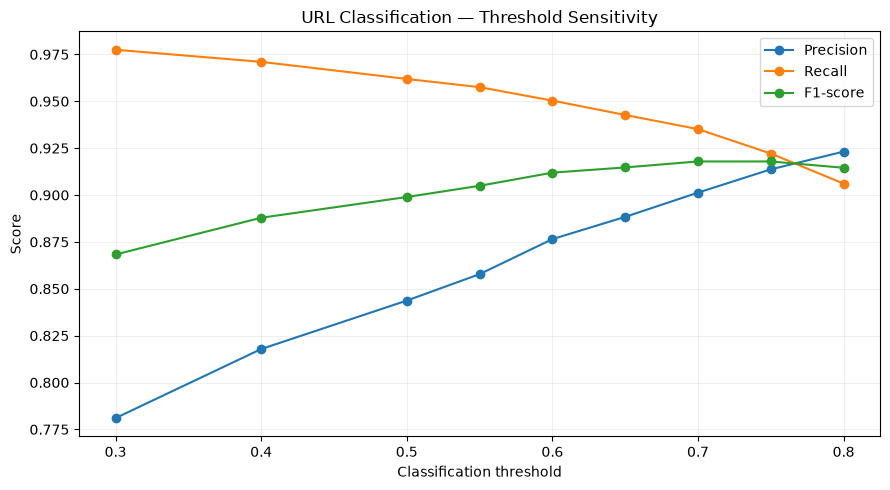

In [48]:
import matplotlib.pyplot as plt

# I visualize how classification metrics change with the threshold.
plt.figure(figsize=(9, 5))

plt.plot(
    url_threshold_comparison["threshold"],
    url_threshold_comparison["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    url_threshold_comparison["threshold"],
    url_threshold_comparison["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    url_threshold_comparison["threshold"],
    url_threshold_comparison["f1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification threshold")
plt.ylabel("Score")
plt.title("URL Classification — Threshold Sensitivity")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

## 8. Final Held-Out Test Evaluation

I selected Histogram Gradient Boosting as my final URL classifier based on its validation performance and robustness analysis.

Using the validation partition, I selected a classification threshold of 0.70 because it provides a strong balance between phishing precision and recall while reducing false-positive predictions.

I now evaluate this fixed model and threshold on the previously untouched test partition.

I report classification metrics, confusion matrices, and structural subgroup performance to assess how well the selected configuration generalizes to unfamiliar hostnames within the same published dataset.

I do not use the test results to modify the fitted model, feature extractor, or classification threshold.

In [51]:
# I load the reserved test partition only after model selection.
url_test = pd.read_csv(
    SPLIT_DIR / "url_v2_test.csv"
)

print("FINAL TEST DATASET")
print("Shape:", url_test.shape)
print("Columns:", url_test.columns.tolist())

print("\nTEST LABEL DISTRIBUTION")
print(url_test["label"].value_counts().sort_index())

assert url_test.columns.tolist() == url_train.columns.tolist()
assert url_test["label"].isin([0, 1]).all()

# I verify that no exact URL appears in multiple partitions.
train_urls = set(url_train["url"])
val_urls = set(url_val["url"])
test_urls = set(url_test["url"])

assert train_urls.isdisjoint(test_urls)
assert val_urls.isdisjoint(test_urls)

print("\nExact URL overlap checks: PASSED")

FINAL TEST DATASET
Shape: (19467, 3)
Columns: ['url', 'label', 'source']

TEST LABEL DISTRIBUTION
label
0    11246
1     8221
Name: count, dtype: int64

Exact URL overlap checks: PASSED


In [53]:
# I use the same feature extractor as training and validation.
start_time = time.perf_counter()

X_url_test = extract_features_dataframe(
    url_test["url"]
)

test_extraction_time = time.perf_counter() - start_time

y_url_test = url_test["label"].reset_index(drop=True)

# I validate the test feature matrix.
assert X_url_test.columns.equals(X_url_train.columns)
assert X_url_test.shape == (len(url_test), 21)
assert np.isfinite(X_url_test.to_numpy()).all()

print("TEST FEATURE EXTRACTION")
print("Shape:", X_url_test.shape)
print(f"Extraction time: {test_extraction_time:.2f} seconds")
print("Feature validation: PASSED")

TEST FEATURE EXTRACTION
Shape: (19467, 21)
Extraction time: 2.04 seconds
Feature validation: PASSED


In [55]:
# I apply the previously selected threshold without modification.
SELECTED_URL_THRESHOLD = 0.70

url_test_probabilities = (
    url_hgb_model.predict_proba(X_url_test)[:, 1]
)

url_test_predictions = (
    url_test_probabilities >= SELECTED_URL_THRESHOLD
).astype(int)

url_final_test_results = evaluate_url_model(
    "Final URL HGB (threshold=0.70)",
    y_url_test,
    url_test_predictions
)

print("\nFINAL MODEL CONFIGURATION")
print("Model: Histogram Gradient Boosting")
print("Threshold:", SELECTED_URL_THRESHOLD)
print("Test records:", len(y_url_test))


FINAL URL HGB (THRESHOLD=0.70) RESULTS
Model: Final URL HGB (threshold=0.70)
Accuracy: 0.7766
Precision: 0.8750
Recall: 0.5494
F1: 0.6750

CONFUSION MATRIX
[[10601   645]
 [ 3704  4517]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.74      0.94      0.83     11246
    Phishing       0.88      0.55      0.68      8221

    accuracy                           0.78     19467
   macro avg       0.81      0.75      0.75     19467
weighted avg       0.80      0.78      0.76     19467


FINAL MODEL CONFIGURATION
Model: Histogram Gradient Boosting
Threshold: 0.7
Test records: 19467


In [57]:
# I examine the selected model across important URL structures.
test_analysis = pd.DataFrame({
    "actual": y_url_test.to_numpy(),
    "predicted": url_test_predictions,
    "is_https": X_url_test["is_https"].to_numpy(),
    "has_path": X_url_test["path_length"].to_numpy() > 0,
    "has_query": X_url_test["has_query"].to_numpy()
})

test_groups = {
    "HTTPS": test_analysis["is_https"] == 1,
    "HTTP / Non-HTTPS": test_analysis["is_https"] == 0,
    "Non-empty path": test_analysis["has_path"],
    "Empty path": ~test_analysis["has_path"],
    "Has query": test_analysis["has_query"] == 1,
    "No query": test_analysis["has_query"] == 0
}

test_subgroup_results = []

for group_name, mask in test_groups.items():

    group = test_analysis.loc[mask]

    tn, fp, fn, tp = confusion_matrix(
        group["actual"],
        group["predicted"],
        labels=[0, 1]
    ).ravel()

    legitimate_count = tn + fp
    phishing_count = tp + fn

    test_subgroup_results.append({
        "subgroup": group_name,
        "records": len(group),
        "legitimate": legitimate_count,
        "phishing": phishing_count,
        "accuracy": (tn + tp) / len(group),
        "phishing_recall": (
            tp / phishing_count
            if phishing_count else np.nan
        ),
        "false_positive_rate": (
            fp / legitimate_count
            if legitimate_count else np.nan
        ),
        "false_positives": int(fp),
        "false_negatives": int(fn)
    })

url_test_subgroup_results = pd.DataFrame(
    test_subgroup_results
)

print("FINAL TEST — STRUCTURAL SUBGROUP PERFORMANCE")

display(
    url_test_subgroup_results.round(4)
)

FINAL TEST — STRUCTURAL SUBGROUP PERFORMANCE


,subgroup,records,legitimate,phishing,accuracy,phishing_recall,false_positive_rate,false_positives,false_negatives
0,HTTPS,17768,10138,7630,0.7655,0.5287,0.0562,570,3596
1,HTTP / Non-HTTPS,1699,1108,591,0.8923,0.8173,0.0677,75,108
2,Non-empty path,18592,11145,7447,0.7702,0.5061,0.0533,594,3678
3,Empty path,875,101,774,0.9120,0.9664,0.5050,51,26
4,Has query,6318,2976,3342,0.4802,0.0482,0.0346,103,3181
5,No query,13149,8270,4879,0.9190,0.8928,0.0655,542,523


## 9. Investigating Validation-to-Test Generalization

My selected Histogram Gradient Boosting model achieved 91.79% phishing F1-score on validation but only 67.50% on the held-out test partition.

The decline was primarily associated with reduced phishing recall, particularly for URLs containing query parameters.

I observed that query-containing phishing URLs represent a much larger proportion of the test partition than the validation partition.

I investigate the distribution of URL structures across training, validation, and test data to understand whether the hostname-aware splitting process produced substantial differences between partitions.

I treat the test results as a diagnostic finding rather than an opportunity to retune the selected classifier.

In [60]:
# I compare URL characteristics across all three partitions.

partition_data = {
    "Train": (X_url_train, y_url_train),
    "Validation": (X_url_val, y_url_val),
    "Test": (X_url_test, y_url_test)
}

distribution_results = []

for partition_name, (X, y) in partition_data.items():

    labels = y.to_numpy()

    for label_value, class_name in [
        (0, "Legitimate"),
        (1, "Phishing")
    ]:

        mask = labels == label_value
        class_features = X.loc[mask]

        distribution_results.append({
            "partition": partition_name,
            "class": class_name,
            "records": int(mask.sum()),
            "https_rate": class_features["is_https"].mean(),
            "query_rate": class_features["has_query"].mean(),
            "nonempty_path_rate": (
                class_features["path_length"] > 0
            ).mean(),
            "mean_url_length": class_features["url_length"].mean(),
            "mean_hostname_length": (
                class_features["hostname_length"].mean()
            ),
            "mean_path_length": (
                class_features["path_length"].mean()
            ),
            "mean_query_length": (
                class_features["query_length"].mean()
            )
        })

url_distribution_comparison = pd.DataFrame(
    distribution_results
)

print("URL FEATURE DISTRIBUTIONS BY PARTITION AND CLASS")

display(
    url_distribution_comparison.round(4)
)

URL FEATURE DISTRIBUTIONS BY PARTITION AND CLASS


,partition,class,records,https_rate,query_rate,nonempty_path_rate,mean_url_length,mean_hostname_length,mean_path_length,mean_query_length
0,Train,Legitimate,52478,0.8732,0.2837,0.9875,89.2274,16.8782,30.9217,33.0536
1,Train,Phishing,38362,0.8811,0.0679,0.8934,59.1248,26.4172,16.6058,7.0869
2,Validation,Legitimate,11246,0.8518,0.2465,0.9900,87.4642,16.8053,42.2454,20.1726
3,Validation,Phishing,8221,0.9279,0.0577,0.9133,71.8448,25.8802,30.1536,4.3079
4,Test,Legitimate,11246,0.9015,0.2646,0.9910,76.7840,18.1940,34.5863,15.7499
5,Test,Phishing,8221,0.9281,0.4065,0.9059,95.9335,24.6047,44.5358,18.3352


In [62]:
# I examine query-containing URLs within each class.

query_results = []

for partition_name, (X, y) in partition_data.items():

    labels = y.to_numpy()
    has_query = X["has_query"].to_numpy() == 1

    for label_value, class_name in [
        (0, "Legitimate"),
        (1, "Phishing")
    ]:

        mask = labels == label_value

        query_results.append({
            "partition": partition_name,
            "class": class_name,
            "total_urls": int(mask.sum()),
            "with_query": int((mask & has_query).sum()),
            "without_query": int((mask & ~has_query).sum()),
            "query_rate": (
                (mask & has_query).sum() / mask.sum()
            )
        })

url_query_distribution = pd.DataFrame(query_results)

print("QUERY PARAMETER DISTRIBUTION")

display(
    url_query_distribution.round(4)
)

QUERY PARAMETER DISTRIBUTION


,partition,class,total_urls,with_query,without_query,query_rate
0,Train,Legitimate,52478,14888,37590,0.2837
1,Train,Phishing,38362,2605,35757,0.0679
2,Validation,Legitimate,11246,2772,8474,0.2465
3,Validation,Phishing,8221,474,7747,0.0577
4,Test,Legitimate,11246,2976,8270,0.2646
5,Test,Phishing,8221,3342,4879,0.4065


# Version 3 — Revised URL Classification Experiments

## Objective

My initial URL classifier achieved 91.79% phishing F1-score on validation but only 67.50% on the original held-out test partition.

I investigated the discrepancy and found substantial structural differences between the partitions, particularly the concentration of query-heavy phishing URLs from `docs.google.com` in the original test set.

I subsequently revised my dataset construction methodology by separating eight exceptionally large hostname groups into a dedicated challenge dataset and generating structurally balanced development partitions.

In this experiment, I retrain my URL classifiers using the revised development data.

I compare Logistic Regression and Histogram Gradient Boosting, examine validation errors, and investigate whether the revised partitions produce more consistent evaluation results.

I reserve the exploratory evaluation and challenge datasets until after model selection.

Because this revision was informed by my earlier test findings, I treat all Version 3 results as retrospective exploratory evidence rather than independent confirmation of model generalization.

In [65]:
# I load the revised training and validation datasets.
url_v3_train = pd.read_csv(
    SPLIT_DIR / "url_v3_train.csv"
)

url_v3_val = pd.read_csv(
    SPLIT_DIR / "url_v3_val.csv"
)

print("VERSION 3 DATASET VERIFICATION")

print("\nTraining")
print("Shape:", url_v3_train.shape)
print(
    url_v3_train["label"]
    .value_counts()
    .sort_index()
)

print("\nValidation")
print("Shape:", url_v3_val.shape)
print(
    url_v3_val["label"]
    .value_counts()
    .sort_index()
)

# I verify the expected partition sizes.
assert len(url_v3_train) == 82357
assert len(url_v3_val) == 17702

assert url_v3_train.columns.tolist() == [
    "url", "label", "source"
]

assert url_v3_val.columns.tolist() == [
    "url", "label", "source"
]

print("\nVersion 3 dataset verification: PASSED")

VERSION 3 DATASET VERIFICATION

Training
Shape: (82357, 3)
label
0    52807
1    29550
Name: count, dtype: int64

Validation
Shape: (17702, 3)
label
0    11495
1     6207
Name: count, dtype: int64

Version 3 dataset verification: PASSED


## Version 3 — Feature Preparation

I reuse the same 21 numerical URL features from my earlier experiments to maintain consistency across dataset versions.

I extract features independently from the revised training and validation partitions, without using their labels or source identifiers as predictive inputs.

I verify that the feature matrices contain no missing or infinite values and that their columns are identical.

I retain the exploratory evaluation and large-hostname challenge datasets for later assessment.

In [68]:
# I extract features from the revised training and validation URLs.
start_time = time.perf_counter()

X_url_v3_train = extract_features_dataframe(
    url_v3_train["url"]
)

v3_train_extraction_time = time.perf_counter() - start_time

start_time = time.perf_counter()

X_url_v3_val = extract_features_dataframe(
    url_v3_val["url"]
)

v3_val_extraction_time = time.perf_counter() - start_time

# I keep the classification labels separate from the features.
y_url_v3_train = url_v3_train["label"].reset_index(drop=True)
y_url_v3_val = url_v3_val["label"].reset_index(drop=True)

print("VERSION 3 FEATURE EXTRACTION")

print(
    f"Training: {X_url_v3_train.shape} "
    f"({v3_train_extraction_time:.2f} seconds)"
)

print(
    f"Validation: {X_url_v3_val.shape} "
    f"({v3_val_extraction_time:.2f} seconds)"
)

VERSION 3 FEATURE EXTRACTION
Training: (82357, 21) (7.48 seconds)
Validation: (17702, 21) (1.54 seconds)


In [70]:
# I verify the shape and consistency of the extracted features.
assert X_url_v3_train.shape == (82357, 21)
assert X_url_v3_val.shape == (17702, 21)

assert X_url_v3_train.columns.equals(
    X_url_v3_val.columns
)

# I check for missing and infinite feature values.
assert np.isfinite(
    X_url_v3_train.to_numpy()
).all()

assert np.isfinite(
    X_url_v3_val.to_numpy()
).all()

# I confirm that features and labels are aligned.
assert len(X_url_v3_train) == len(y_url_v3_train)
assert len(X_url_v3_val) == len(y_url_v3_val)

# I ensure both partitions use binary labels.
assert set(y_url_v3_train.unique()) == {0, 1}
assert set(y_url_v3_val.unique()) == {0, 1}

print("VERSION 3 FEATURE VALIDATION")

print("Features:", X_url_v3_train.shape[1])
print("Feature columns: IDENTICAL")
print("Missing/infinite values: NONE")
print("Label alignment: PASSED")
print("Overall validation: PASSED")

VERSION 3 FEATURE VALIDATION
Features: 21
Feature columns: IDENTICAL
Missing/infinite values: NONE
Label alignment: PASSED
Overall validation: PASSED


## Version 3 — Model Training and Validation

I retrain Logistic Regression and Histogram Gradient Boosting using the revised development dataset.

I retain the same model configurations and 21 URL features from my earlier experiments so that I can compare their performance without introducing additional modeling changes.

My objective is to establish whether the revised partitions support more consistent classification results.

I evaluate both models on the Version 3 validation partition using the default classification threshold of 0.50.

I reserve the exploratory evaluation and large-hostname challenge datasets until after model selection.

Because this experiment follows an investigation of the original test results, I treat the findings as retrospective exploratory evidence.

In [77]:

# I retain the original Logistic Regression configuration.
url_v3_logreg = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        LogisticRegression(
            C=1.0,
            class_weight=None,
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

start_time = time.perf_counter()

url_v3_logreg.fit(
    X_url_v3_train,
    y_url_v3_train
)

v3_logreg_training_time = time.perf_counter() - start_time

url_v3_logreg_predictions = url_v3_logreg.predict(
    X_url_v3_val
)

url_v3_logreg_probabilities = (
    url_v3_logreg.predict_proba(X_url_v3_val)[:, 1]
)

print("VERSION 3 — LOGISTIC REGRESSION")
print(f"Training time: {v3_logreg_training_time:.2f} seconds")

url_v3_logreg_results = evaluate_url_model(
    "V3 Logistic Regression",
    y_url_v3_val,
    url_v3_logreg_predictions
)

VERSION 3 — LOGISTIC REGRESSION
Training time: 0.76 seconds

V3 LOGISTIC REGRESSION RESULTS
Model: V3 Logistic Regression
Accuracy: 0.8637
Precision: 0.8207
Recall: 0.7822
F1: 0.8010

CONFUSION MATRIX
[[10434  1061]
 [ 1352  4855]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.89      0.91      0.90     11495
    Phishing       0.82      0.78      0.80      6207

    accuracy                           0.86     17702
   macro avg       0.85      0.84      0.85     17702
weighted avg       0.86      0.86      0.86     17702



In [79]:
# I retain the original Histogram Gradient Boosting configuration.
url_v3_hgb = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_iter=150,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=RANDOM_STATE
)

start_time = time.perf_counter()

url_v3_hgb.fit(
    X_url_v3_train,
    y_url_v3_train
)

v3_hgb_training_time = time.perf_counter() - start_time

url_v3_hgb_predictions = url_v3_hgb.predict(
    X_url_v3_val
)

url_v3_hgb_probabilities = (
    url_v3_hgb.predict_proba(X_url_v3_val)[:, 1]
)

print("VERSION 3 — HISTOGRAM GRADIENT BOOSTING")
print(f"Training time: {v3_hgb_training_time:.2f} seconds")
print("Boosting iterations:", url_v3_hgb.n_iter_)

url_v3_hgb_results = evaluate_url_model(
    "V3 Histogram Gradient Boosting",
    y_url_v3_val,
    url_v3_hgb_predictions
)

VERSION 3 — HISTOGRAM GRADIENT BOOSTING
Training time: 3.23 seconds
Boosting iterations: 150

V3 HISTOGRAM GRADIENT BOOSTING RESULTS
Model: V3 Histogram Gradient Boosting
Accuracy: 0.9091
Precision: 0.8736
Recall: 0.8661
F1: 0.8698

CONFUSION MATRIX
[[10717   778]
 [  831  5376]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.93      0.93      0.93     11495
    Phishing       0.87      0.87      0.87      6207

    accuracy                           0.91     17702
   macro avg       0.90      0.90      0.90     17702
weighted avg       0.91      0.91      0.91     17702



In [81]:
# I compare both classifiers on the same validation partition.
v3_model_comparison = pd.DataFrame([
    url_v3_logreg_results,
    url_v3_hgb_results
])

v3_model_comparison = (
    v3_model_comparison
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

print("VERSION 3 — MODEL COMPARISON")

display(v3_model_comparison.round(4))

VERSION 3 — MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1
0,V3 Histogram Gradient Boosting,0.9091,0.8736,0.8661,0.8698
1,V3 Logistic Regression,0.8637,0.8207,0.7822,0.8010


## Version 3 — Classification Threshold Analysis

I selected Histogram Gradient Boosting as the leading classifier based on its Version 3 validation performance.

At the default threshold of 0.50, the classifier achieved 87.36% phishing precision, 86.61% recall, and 86.98% F1-score.

I now evaluate alternative decision thresholds to understand how the model balances false-positive warnings against missed phishing URLs.

I consider both F1-score and phishing recall when selecting an operating threshold, because missing a phishing URL may have greater consequences than incorrectly warning about a legitimate URL.

I use only the validation partition for this decision. The exploratory evaluation and large-hostname challenge datasets remain unused during threshold selection.

In [84]:
# I evaluate predefined classification thresholds.
v3_thresholds = [
    0.30, 0.35, 0.40, 0.45,
    0.50, 0.55, 0.60, 0.65,
    0.70, 0.75, 0.80
]

v3_threshold_results = []

for threshold in v3_thresholds:

    predictions = (
        url_v3_hgb_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_url_v3_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    v3_threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(
            y_url_v3_val, predictions
        ),
        "precision": precision_score(
            y_url_v3_val, predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_url_v3_val, predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_url_v3_val, predictions,
            zero_division=0
        ),
        "false_positive_rate": fp / (fp + tn),
        "false_positives": int(fp),
        "false_negatives": int(fn)
    })

v3_threshold_comparison = pd.DataFrame(
    v3_threshold_results
)

print("VERSION 3 — THRESHOLD COMPARISON")

display(
    v3_threshold_comparison.round(4)
)

VERSION 3 — THRESHOLD COMPARISON


,threshold,accuracy,precision,recall,f1,false_positive_rate,false_positives,false_negatives
0,0.30,0.8950,0.8111,0.9133,0.8592,0.1148,1320,538
1,0.35,0.8996,0.8287,0.8996,0.8627,0.1004,1154,623
2,0.40,0.8998,0.8393,0.8834,0.8608,0.0913,1050,724
3,0.45,0.9019,0.8487,0.8766,0.8624,0.0844,970,766
4,0.50,0.9091,0.8736,0.8661,0.8698,0.0677,778,831
5,0.55,0.9101,0.8810,0.8598,0.8703,0.0627,721,870
6,0.60,0.9116,0.8913,0.8519,0.8712,0.0561,645,919
7,0.65,0.9133,0.9039,0.8423,0.8720,0.0484,556,979
8,0.70,0.9126,0.9118,0.8312,0.8696,0.0434,499,1048
9,0.75,0.9110,0.9254,0.8115,0.8647,0.0353,406,1170


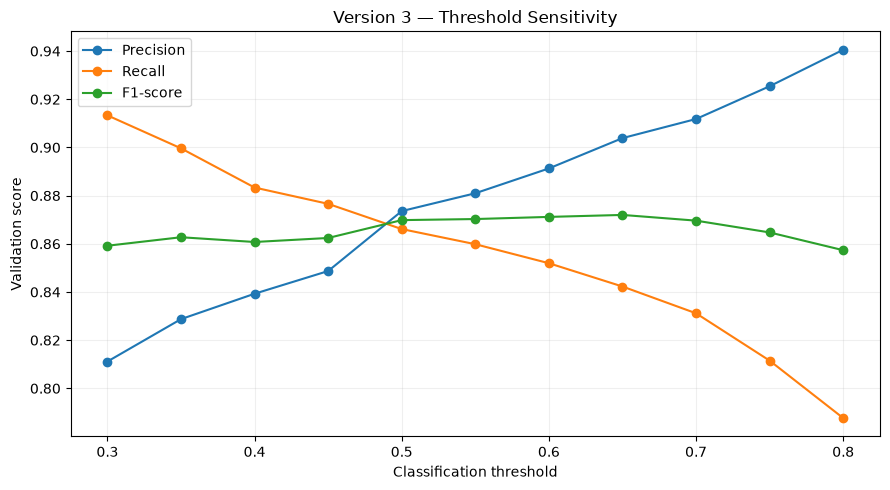

In [86]:
import matplotlib.pyplot as plt

# I visualize classification performance across thresholds.
plt.figure(figsize=(9, 5))

plt.plot(
    v3_threshold_comparison["threshold"],
    v3_threshold_comparison["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    v3_threshold_comparison["threshold"],
    v3_threshold_comparison["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    v3_threshold_comparison["threshold"],
    v3_threshold_comparison["f1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Classification threshold")
plt.ylabel("Validation score")
plt.title("Version 3 — Threshold Sensitivity")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

## Version 3 — Exploratory Evaluation

I selected Histogram Gradient Boosting as my preferred URL classifier because it outperformed Logistic Regression on the revised validation partition.

I retained the default classification threshold of 0.50. Although a threshold of 0.65 achieved a slightly higher validation F1-score, it also increased the number of missed phishing URLs. Given the security-related purpose of my application, I preferred the more balanced precision–recall relationship at 0.50.

I now evaluate the fixed classifier on the Version 3 exploratory evaluation partition.

My objective is to determine whether performance remains reasonably consistent across the revised hostname-disjoint development partitions.

Because I developed this partitioning strategy after examining my original test results, I treat this evaluation as retrospective rather than independent confirmation of generalization.


In [89]:
# I load the revised exploratory evaluation dataset.
url_v3_eval = pd.read_csv(
    SPLIT_DIR / "url_v3_eval.csv"
)

print("VERSION 3 — EXPLORATORY EVALUATION")

print("Dataset shape:", url_v3_eval.shape)

print("\nClass distribution:")
print(
    url_v3_eval["label"]
    .value_counts()
    .sort_index()
)

# I extract features using the existing URL feature extractor.
start_time = time.perf_counter()

X_url_v3_eval = extract_features_dataframe(
    url_v3_eval["url"]
)

eval_extraction_time = time.perf_counter() - start_time

y_url_v3_eval = (
    url_v3_eval["label"]
    .reset_index(drop=True)
)

# I validate feature consistency.
assert X_url_v3_eval.shape == (16380, 21)

assert X_url_v3_eval.columns.equals(
    X_url_v3_train.columns
)

assert np.isfinite(
    X_url_v3_eval.to_numpy()
).all()

print("\nFeature shape:", X_url_v3_eval.shape)

print(
    f"Feature extraction time: "
    f"{eval_extraction_time:.2f} seconds"
)

print("Feature validation: PASSED")

VERSION 3 — EXPLORATORY EVALUATION
Dataset shape: (16380, 3)

Class distribution:
label
0    10386
1     5994
Name: count, dtype: int64

Feature shape: (16380, 21)
Feature extraction time: 1.45 seconds
Feature validation: PASSED


In [91]:
# I retain my validation-selected classifier and threshold.
V3_SELECTED_THRESHOLD = 0.50

# I generate phishing probabilities.
url_v3_eval_probabilities = (
    url_v3_hgb.predict_proba(
        X_url_v3_eval
    )[:, 1]
)

# I apply the fixed classification threshold.
url_v3_eval_predictions = (
    url_v3_eval_probabilities
    >= V3_SELECTED_THRESHOLD
).astype(int)

# I evaluate the model without modifying its configuration.
url_v3_eval_results = evaluate_url_model(
    "V3 HGB — Exploratory Evaluation",
    y_url_v3_eval,
    url_v3_eval_predictions
)


V3 HGB — EXPLORATORY EVALUATION RESULTS
Model: V3 HGB — Exploratory Evaluation
Accuracy: 0.9129
Precision: 0.8704
Recall: 0.8954
F1: 0.8827

CONFUSION MATRIX
[[9587  799]
 [ 627 5367]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.94      0.92      0.93     10386
    Phishing       0.87      0.90      0.88      5994

    accuracy                           0.91     16380
   macro avg       0.90      0.91      0.91     16380
weighted avg       0.91      0.91      0.91     16380



In [93]:
# I compare performance across the revised development partitions.

v3_generalization_comparison = pd.DataFrame([
    {
        "Partition": "Validation",
        **url_v3_hgb_results
    },
    {
        "Partition": "Exploratory Evaluation",
        **url_v3_eval_results
    }
])

display(
    v3_generalization_comparison[
        [
            "Partition",
            "Accuracy",
            "Precision",
            "Recall",
            "F1"
        ]
    ].round(4)
)

,Partition,Accuracy,Precision,Recall,F1
0,Validation,0.9091,0.8736,0.8661,0.8698
1,Exploratory Evaluation,0.9129,0.8704,0.8954,0.8827


## Version 3 — Large-Hostname Challenge Evaluation

My Version 3 classifier achieved 86.98% phishing F1-score on validation and 88.27% on the exploratory evaluation partition.

These results suggest that the revised development partitions provide more consistent performance estimates for the subset of URLs used during model development.

However, I deliberately excluded eight hostname groups containing at least 500 records from training and validation.

These groups represent a substantial portion of the phishing dataset and include hosting platforms with considerably different URL structures.

I now evaluate my selected Histogram Gradient Boosting classifier against this separate challenge dataset.

I retain the previously selected classification threshold of 0.50 and do not modify the fitted model.

Because the challenge dataset is heavily dominated by phishing-labeled URLs, I focus particularly on phishing recall and hostname-specific classification errors.

I treat this evaluation as retrospective evidence of model robustness rather than an independent final benchmark.

In [96]:
# I load the large-hostname challenge dataset.
url_v3_challenge = pd.read_csv(
    SPLIT_DIR / "url_v3_challenge.csv"
)

print("VERSION 3 — CHALLENGE DATASET")

print("Shape:", url_v3_challenge.shape)

print("\nClass distribution:")
print(
    url_v3_challenge["label"]
    .value_counts()
    .sort_index()
)

# I extract the same 21 URL features.
start_time = time.perf_counter()

X_url_v3_challenge = extract_features_dataframe(
    url_v3_challenge["url"]
)

challenge_extraction_time = (
    time.perf_counter() - start_time
)

y_url_v3_challenge = (
    url_v3_challenge["label"]
    .reset_index(drop=True)
)

# I verify feature consistency.
assert X_url_v3_challenge.shape == (13335, 21)

assert X_url_v3_challenge.columns.equals(
    X_url_v3_train.columns
)

assert np.isfinite(
    X_url_v3_challenge.to_numpy()
).all()

print("\nFeature shape:", X_url_v3_challenge.shape)

print(
    f"Extraction time: "
    f"{challenge_extraction_time:.2f} seconds"
)

print("Feature validation: PASSED")

VERSION 3 — CHALLENGE DATASET
Shape: (13335, 3)

Class distribution:
label
0      282
1    13053
Name: count, dtype: int64

Feature shape: (13335, 21)
Extraction time: 1.28 seconds
Feature validation: PASSED


In [98]:
# I apply the fixed Version 3 model and threshold.
url_v3_challenge_probabilities = (
    url_v3_hgb.predict_proba(
        X_url_v3_challenge
    )[:, 1]
)

url_v3_challenge_predictions = (
    url_v3_challenge_probabilities
    >= V3_SELECTED_THRESHOLD
).astype(int)

url_v3_challenge_results = evaluate_url_model(
    "V3 HGB — Large-Hostname Challenge",
    y_url_v3_challenge,
    url_v3_challenge_predictions
)


V3 HGB — LARGE-HOSTNAME CHALLENGE RESULTS
Model: V3 HGB — Large-Hostname Challenge
Accuracy: 0.5210
Precision: 0.9960
Recall: 0.5128
F1: 0.6770

CONFUSION MATRIX
[[ 255   27]
 [6360 6693]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Legitimate       0.04      0.90      0.07       282
    Phishing       1.00      0.51      0.68     13053

    accuracy                           0.52     13335
   macro avg       0.52      0.71      0.38     13335
weighted avg       0.98      0.52      0.66     13335



In [100]:
from urllib.parse import urlsplit

# I extract hostnames for challenge-level analysis.
def challenge_hostname(url):
    try:
        return (urlsplit(str(url)).hostname or "").lower()
    except ValueError:
        return ""


challenge_analysis = pd.DataFrame({
    "hostname": (
        url_v3_challenge["url"]
        .map(challenge_hostname)
        .to_numpy()
    ),
    "actual": y_url_v3_challenge.to_numpy(),
    "predicted": url_v3_challenge_predictions
})

challenge_hostname_results = []

for hostname, group in challenge_analysis.groupby("hostname"):

    tn, fp, fn, tp = confusion_matrix(
        group["actual"],
        group["predicted"],
        labels=[0, 1]
    ).ravel()

    phishing_count = tp + fn
    legitimate_count = tn + fp

    challenge_hostname_results.append({
        "hostname": hostname,
        "records": len(group),
        "legitimate": legitimate_count,
        "phishing": phishing_count,
        "phishing_recall": (
            tp / phishing_count
            if phishing_count else np.nan
        ),
        "false_positive_rate": (
            fp / legitimate_count
            if legitimate_count else np.nan
        ),
        "false_positives": int(fp),
        "false_negatives": int(fn)
    })

challenge_hostname_performance = (
    pd.DataFrame(challenge_hostname_results)
    .sort_values("records", ascending=False)
    .reset_index(drop=True)
)

print("VERSION 3 — CHALLENGE PERFORMANCE BY HOSTNAME")

display(
    challenge_hostname_performance.round(4)
)

VERSION 3 — CHALLENGE PERFORMANCE BY HOSTNAME


,hostname,records,legitimate,phishing,phishing_recall,false_positive_rate,false_positives,false_negatives
0,cloudflare-ipfs.com,3220,0,3220,0.9953,NaN,0,15
1,docs.google.com,3165,0,3165,0.0044,NaN,0,3151
2,ipfs.eth.aragon.network,2180,0,2180,0.9922,NaN,0,17
3,cf-ipfs.com,1354,0,1354,0.1189,NaN,0,1193
4,new.express.adobe.com,949,0,949,0.6228,NaN,0,358
5,tinyurl.com,932,282,650,0.3938,0.0957,27,394
6,ipfs.io,877,0,877,0.3261,NaN,0,591
7,sites.google.com,658,0,658,0.0258,NaN,0,641


### Large-Hostname Challenge Evaluation Findings

My Version 3 Histogram Gradient Boosting classifier achieved 86.98% phishing F1-score on validation and 88.27% on the exploratory evaluation partition.

However, performance declined substantially on the separate large-hostname challenge dataset, where phishing recall fell to 51.28%.

The challenge dataset contained 13,335 URLs from eight hostnames excluded from Version 3 training and validation. Of its 13,053 phishing-labeled URLs, my classifier missed 6,360.

The results differed significantly between hostnames. The model achieved more than 99% phishing recall on `cloudflare-ipfs.com` and `ipfs.eth.aragon.network`, but only 0.44% on `docs.google.com` and 2.58% on `sites.google.com`.

These findings showed me that consistent performance across my development partitions did not guarantee reliable detection of phishing URLs hosted on unfamiliar platforms.

The model appears to recognize certain URL structures effectively while struggling with others, particularly URLs hosted on legitimate third-party services.

I therefore retain Histogram Gradient Boosting as my exploratory URL classification baseline rather than treating it as a fully validated security detector.

I also recognize that lexical URL analysis alone may be insufficient for identifying phishing content hosted on otherwise legitimate platforms.

I will preserve these limitations in my technical documentation and ensure that any future application does not interpret a negative model prediction as proof that a URL is safe.

## Version 3 — Model Serialization and Reproducibility

I retain Histogram Gradient Boosting as my preferred URL classification research baseline.

The model achieved 86.98% phishing F1-score on validation and 88.27% on the exploratory evaluation partition. However, phishing recall declined to 51.28% on the large-hostname challenge dataset.

I save the fitted classifier alongside its selected decision threshold, feature configuration, and evaluation results.

I preserve these limitations because the classifier is not sufficiently validated to serve as a standalone URL safety checker.

I also verify that reloading the serialized model produces identical predictions, ensuring that the model can be integrated into my application without changing its behavior.

In [105]:
import joblib
import json
import sklearn
from datetime import datetime, timezone

# I configure output directories.
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

# I save the fitted Version 3 classifier.
v3_model_path = MODELS_DIR / "url_v3_hgb_model.joblib"

joblib.dump(
    url_v3_hgb,
    v3_model_path
)

print("MODEL SERIALIZATION")
print("Saved:", v3_model_path)
print(f"File size: {v3_model_path.stat().st_size / 1024:.2f} KB")

MODEL SERIALIZATION
Saved: C:\Users\JONATHAN\Desktop\WORK\spam-phishing-detector\models\url_v3_hgb_model.joblib
File size: 545.52 KB


In [107]:
# I record the configuration required for reproducible inference.

v3_model_config = {
    "model_name": "Histogram Gradient Boosting",
    "model_version": "v3",
    "model_role": "research_baseline",

    "dataset_version": "v3",
    "decision_threshold": float(V3_SELECTED_THRESHOLD),

    "label_mapping": {
        "0": "legitimate",
        "1": "phishing"
    },

    "feature_extractor": "src/url_features.py",
    "feature_names": X_url_v3_train.columns.tolist(),
    "feature_count": int(X_url_v3_train.shape[1]),

    "training_records": int(len(y_url_v3_train)),
    "validation_records": int(len(y_url_v3_val)),

    "sklearn_version": sklearn.__version__,

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "limitations": [
        "Model uses URL-string features only.",
        "Low phishing probability does not establish URL safety.",
        "Version 3 evaluation is retrospective and exploratory.",
        "Large-hostname challenge recall is substantially below development recall.",
        "Model has not been independently validated for production security use."
    ]
}

v3_config_path = (
    MODELS_DIR / "url_v3_model_config.json"
)

with open(v3_config_path, "w", encoding="utf-8") as file:
    json.dump(v3_model_config, file, indent=2)

print("MODEL CONFIGURATION")
print("Saved:", v3_config_path)
print("Decision threshold:", v3_model_config["decision_threshold"])
print("Feature count:", v3_model_config["feature_count"])

MODEL CONFIGURATION
Saved: C:\Users\JONATHAN\Desktop\WORK\spam-phishing-detector\models\url_v3_model_config.json
Decision threshold: 0.5
Feature count: 21


In [109]:
# I preserve the evaluation evidence for the research baseline.

def serialize_metrics(results):
    return {
        key: (
            float(value)
            if isinstance(value, (float, np.floating))
            else value
        )
        for key, value in results.items()
    }


v3_evaluation_report = {
    "model_version": "v3",
    "threshold": float(V3_SELECTED_THRESHOLD),

    "evaluation_status": "retrospective_exploratory",

    "validation": serialize_metrics(
        url_v3_hgb_results
    ),

    "exploratory_evaluation": serialize_metrics(
        url_v3_eval_results
    ),

    "large_hostname_challenge": serialize_metrics(
        url_v3_challenge_results
    ),

    "challenge_hostname_performance": (
        challenge_hostname_performance
        .replace({np.nan: None})
        .to_dict(orient="records")
    ),

    "interpretation": (
        "Development performance was relatively consistent, "
        "but the classifier showed substantial generalization "
        "weaknesses across unfamiliar hosting platforms."
    )
}

v3_results_path = (
    OUTPUTS_DIR / "url_v3_evaluation_results.json"
)

with open(v3_results_path, "w", encoding="utf-8") as file:
    json.dump(
        v3_evaluation_report,
        file,
        indent=2
    )

print("EVALUATION RESULTS")
print("Saved:", v3_results_path)

EVALUATION RESULTS
Saved: C:\Users\JONATHAN\Desktop\WORK\spam-phishing-detector\outputs\url_v3_evaluation_results.json


In [111]:
# I reload the saved classifier and its configuration.

loaded_url_model = joblib.load(
    v3_model_path
)

with open(
    v3_config_path,
    "r",
    encoding="utf-8"
) as file:
    loaded_url_config = json.load(file)

loaded_threshold = (
    loaded_url_config["decision_threshold"]
)

loaded_feature_names = (
    loaded_url_config["feature_names"]
)

print("MODEL RELOAD")

print("Model:", type(loaded_url_model).__name__)
print("Threshold:", loaded_threshold)
print("Expected features:", len(loaded_feature_names))

MODEL RELOAD
Model: HistGradientBoostingClassifier
Threshold: 0.5
Expected features: 21


In [113]:
# I verify that the reloaded model reproduces original predictions.

sample_features = (
    X_url_v3_val
    .iloc[:100]
    .copy()
)

# I preserve the feature order used during training.
sample_features = sample_features[
    loaded_feature_names
]

original_probabilities = (
    url_v3_hgb.predict_proba(
        sample_features
    )[:, 1]
)

reloaded_probabilities = (
    loaded_url_model.predict_proba(
        sample_features
    )[:, 1]
)

# I verify numerical consistency.
np.testing.assert_allclose(
    original_probabilities,
    reloaded_probabilities,
    rtol=1e-12,
    atol=1e-12
)

original_predictions = (
    original_probabilities >= V3_SELECTED_THRESHOLD
).astype(int)

reloaded_predictions = (
    reloaded_probabilities >= loaded_threshold
).astype(int)

assert np.array_equal(
    original_predictions,
    reloaded_predictions
)

assert loaded_feature_names == (
    X_url_v3_train.columns.tolist()
)

print("SERIALIZATION VERIFICATION")

print("Sample records:", len(sample_features))
print("Probability consistency: PASSED")
print("Prediction consistency: PASSED")
print("Feature order: PASSED")
print("Threshold consistency: PASSED")

print("\nVERSION 3 MODEL VERIFICATION: PASSED")

SERIALIZATION VERIFICATION
Sample records: 100
Probability consistency: PASSED
Prediction consistency: PASSED
Feature order: PASSED
Threshold consistency: PASSED

VERSION 3 MODEL VERIFICATION: PASSED
